# HW2 — Multi-Agent Systems
## Multi-agent simulation of the Public Goods Game with Cheap Talk

**Model:** Qwen2.5-7B-Instruct, 4-bit quantised, Kaggle GPU
**Setup:** 4 agents, 10 rounds, 3 scenarios x 3 runs = **660 successful model calls**

---

### What this notebook does

1. Installs the extra packages and checks the GPU.
2. Adds the project code to `sys.path` — the code comes from a **Kaggle dataset**, it is not written by the notebook.
3. Prepares the Persian font used by the report.
4. Downloads and loads Qwen2.5-7B-Instruct in 4-bit.
5. Runs a two-call smoke test on the backend.
6. Runs all nine games and writes `logs/`.
7. Verifies the 660-call budget and that retries stay out of the game logs.
8. Builds every figure and index required by section 4 of the assignment.
9. Generates `report.html` and converts it to `report.pdf`.

### Dataset layout expected by this notebook

```
hw2-src/
└── pgg/
    ├── __init__.py
    ├── config.py        # all numbers and all model-facing text
    ├── common.py        # records shared by every layer + text helpers
    ├── engine.py        # payoff function and the round loop
    ├── agents.py        # four agent types and the roster factory
    ├── backends.py      # Qwen wrapper + a fake backend
    ├── runner.py        # nine games, writes logs/
    ├── analysis.py      # figures and indices for section 4
    ├── report.py        # report.html -> report.pdf
    ├── submission.py    # packages the final zip
    └── phases/
        ├── chat.py
        └── contribution.py
```

Kaggle settings required: `Settings → Internet → On` and
`Session options → Accelerator → GPU T4 x2`.

## 1. Environment setup

In [1]:
!pip install -q -U bitsandbytes accelerate pydantic matplotlib weasyprint pymupdf 2>&1 | tail -3

# WeasyPrint needs pango/cairo; the Kaggle image ships them, but make the
# dependency explicit so a missing library fails here and not at report time.
import weasyprint, pymupdf
print('weasyprint', weasyprint.__version__, '| pymupdf', pymupdf.__version__)


bigframes 2.51.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
ydata-profiling 4.18.4 requires matplotlib<=3.10,>=3.5, but you have matplotlib 3.11.2 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
weasyprint 70.0 | pymupdf 2.1


In [2]:
import sys, torch

print("python :", sys.version.split()[0])
print("torch  :", torch.__version__)
print("cuda   :", torch.cuda.is_available())
if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        props = torch.cuda.get_device_properties(i)
        print(f"  GPU {i}: {props.name}  ({props.total_memory / 1e9:.1f} GB)")

python : 3.13.16
torch  : 2.11.0+cu130
cuda   : True
  GPU 0: Tesla T4  (15.6 GB)
  GPU 1: Tesla T4  (15.6 GB)


## 2. Attach the project code

The package lives in a Kaggle dataset. Change `PROJECT_ROOT` only if your
dataset folder has a different name; otherwise the automatic search finds it.

In [3]:
import sys, pathlib

PROJECT_ROOT = pathlib.Path("/kaggle/input/hw2-src")

if not PROJECT_ROOT.exists():
    for candidate in pathlib.Path("/kaggle/input").rglob("pgg/config.py"):
        PROJECT_ROOT = candidate.parent.parent
        break

print("project root:", PROJECT_ROOT)
assert (PROJECT_ROOT / "pgg" / "config.py").exists(), "pgg/ not found in the attached datasets"

sys.path.insert(0, str(PROJECT_ROOT))

import pgg
from pgg import config, common, engine, agents, backends, runner, analysis, report

print("imported from", pgg.__file__)
print("N_PLAYERS, N_ROUNDS, ENDOWMENT, MULTIPLIER =",
      config.N_PLAYERS, config.N_ROUNDS, config.ENDOWMENT, config.MULTIPLIER)
print("calls per scenario:", config.EXPECTED_CALLS, "| total:", config.EXPECTED_TOTAL)

project root: /kaggle/input/datasets/mohammadhossein20/public-goods-game-dataset
imported from /kaggle/input/datasets/mohammadhossein20/public-goods-game-dataset/pgg/__init__.py
N_PLAYERS, N_ROUNDS, ENDOWMENT, MULTIPLIER = 4 10 20 1.6
calls per scenario: {1: 80, 2: 80, 3: 60} | total: 660


## 3. Report font

The report is rendered with Vazirmatn. If the font is not part of a dataset it is
downloaded once from the official release.

In [4]:
import io, pathlib, urllib.request, zipfile

ASSETS = pathlib.Path("/kaggle/working/assets")
ASSETS.mkdir(parents=True, exist_ok=True)
NEEDED = ["Vazirmatn-Regular.ttf", "Vazirmatn-Bold.ttf"]

for base in (pathlib.Path("/kaggle/input"), pathlib.Path(".")):
    if not base.exists():
        continue
    for name in NEEDED:
        if (ASSETS / name).exists():
            continue
        for hit in base.rglob(name):
            (ASSETS / name).write_bytes(hit.read_bytes())
            break

if not all((ASSETS / n).exists() for n in NEEDED):
    print("downloading Vazirmatn...")
    url = ("https://github.com/rastikerdar/vazirmatn/releases/download/"
           "v33.003/vazirmatn-v33.003.zip")
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    blob = urllib.request.urlopen(req, timeout=120).read()
    with zipfile.ZipFile(io.BytesIO(blob)) as z:
        for entry in z.namelist():
            if pathlib.Path(entry).name in NEEDED:
                (ASSETS / pathlib.Path(entry).name).write_bytes(z.read(entry))

print({p.name: f"{p.stat().st_size // 1024} KB" for p in ASSETS.glob("*.ttf")})

downloading Vazirmatn...
{'Vazirmatn-Regular.ttf': '119 KB', 'Vazirmatn-Bold.ttf': '120 KB'}


## 4. Load the model

Qwen2.5-7B-Instruct is loaded in 4-bit (nf4 + double quant), which fits on a T4
(about 5.5 GB of weights). The download happens here; the loaded model is then
injected into the backend, so the experiment code never touches HuggingFace.

In [5]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

MODEL_ID = "Qwen/Qwen2.5-7B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

bnb = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=bnb,
    device_map="auto",
)
model.eval()

print("loaded:", MODEL_ID)
print("device map:", getattr(model, "hf_device_map", "single device"))

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/27.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

loaded: Qwen/Qwen2.5-7B-Instruct
device map: {'model.embed_tokens': 0, 'model.layers.0': 0, 'model.layers.1': 0, 'model.layers.2': 0, 'model.layers.3': 0, 'model.layers.4': 0, 'model.layers.5': 0, 'model.layers.6': 0, 'model.layers.7': 0, 'model.layers.8': 0, 'model.layers.9': 0, 'model.layers.10': 0, 'model.layers.11': 0, 'model.layers.12': 1, 'model.layers.13': 1, 'model.layers.14': 1, 'model.layers.15': 1, 'model.layers.16': 1, 'model.layers.17': 1, 'model.layers.18': 1, 'model.layers.19': 1, 'model.layers.20': 1, 'model.layers.21': 1, 'model.layers.22': 1, 'model.layers.23': 1, 'model.layers.24': 1, 'model.layers.25': 1, 'model.layers.26': 1, 'model.layers.27': 1, 'model.norm': 1, 'model.rotary_emb': 1, 'lm_head': 1}


## 5. Backend smoke test

One call per phase before spending the GPU budget, to confirm the model returns
parseable JSON and that the prompt is assembled correctly.

In [6]:
from pgg.backends import QwenBackend
from pgg.agents import LLMAgent

backend = QwenBackend(model, tokenizer, model_id=MODEL_ID)

probe = LLMAgent(1, "machiavellian", backend,
                 config.rules_prompt(known_horizon=True),
                 temperature=config.TEMPERATURE, seed=101)

obs = {"agent_id": 1, "round": 1, "known_horizon": True, "balance": 0.0, "history": []}
chat_reply = probe.chat(obs)
print("chat phase  :", chat_reply)

transcript = {
    1: (chat_reply or {}).get("chat_message", "I plan to contribute 20."),
    2: "I plan to contribute 20 this round.",
    3: "I plan to contribute 15 this round.",
    4: "I plan to contribute 10 this round.",
}
obs2 = dict(obs, round_chat=transcript,
            my_claim=(chat_reply or {}).get("claimed_contribution", 20))
print("contribution:", probe.contribute(obs2))
print("retries/errors so far:", len(probe.errors))

chat phase  : {'chat_message': "Let's all contribute generously! I aim to give 15 tokens.", 'claimed_contribution': 15}
contribution: {'reasoning': 'Maximizing payoff by contributing less than announced, exploiting trust.', 'contribution': 10, 'considers_end': 'group_trust'}
retries/errors so far: 0


## 6. Run all nine games

| Scenario | Roster | Horizon | Calls per run |
|---|---|---|---|
| 1 | 4 heterogeneous LLM agents | known (T=10) | 80 |
| 2 | 4 heterogeneous LLM agents | unknown | 80 |
| 3 | 3 LLM agents + 1 rule-based defector | known (T=10) | 60 |

The rule-based agent consumes no model calls. Expected runtime: ~40-55 minutes.

In [7]:
from pathlib import Path
import time

from pgg.runner import run_all

WORK = Path("/kaggle/working")
started = time.time()
summary = run_all(backend, WORK)
print(f"finished in {(time.time() - started) / 60:.1f} minutes")
summary

finished in 51.4 minutes


{'total_calls': 660,
 'expected_total': 660,
 'by_scenario': {1: 240, 2: 240, 3: 180},
 'runs': 9,
 'structural_errors': 53,
 'temperature': 0.8}

## 7. Verify the 660-call budget

`json.loads` turns object keys into strings, hence `"1"` rather than `1`.

In [8]:
import json, pathlib

idx = json.loads((WORK / "logs/index.json").read_text())
print(json.dumps(idx, indent=2))

assert idx["total_calls"] == 660, f"budget broken: {idx['total_calls']}"
assert idx["by_scenario"] == {"1": 240, "2": 240, "3": 180}, idx["by_scenario"]

files = sorted(WORK.glob("logs/scenario*/run*.json"))
print(f"\n{len(files)} game logs written")

# section 3.3: retried calls must not appear in the game log
game_log = (WORK / "logs/scenario1/run1.json").read_text()
assert "attempts" not in game_log and "raw_response" not in game_log
print("OK: game logs are clean; retries are isolated in logs/diagnostics/")

{
  "total_calls": 660,
  "expected_total": 660,
  "by_scenario": {
    "1": 240,
    "2": 240,
    "3": 180
  },
  "runs": 9,
  "structural_errors": 53,
  "temperature": 0.8
}

9 game logs written
OK: game logs are clean; retries are isolated in logs/diagnostics/


## 8. Analysis (assignment section 4)

Every number is averaged over the three independent runs of each scenario.

In [9]:
import os
from pgg.analysis import build_all, load_logs
from pgg.config import ENDOWMENT

os.chdir(WORK)
logs = load_logs(Path("."))
assert len(logs) == 9, len(logs)

results = build_all(logs, Path("."))
for name, path in results["figures"].items():
    print(f"  {name} -> {path}")


  contribution_curves -> figures/01_contribution_curves.png
  scenario_comparison -> figures/02_scenario_comparison.png
  agent_trajectories_s1 -> figures/03_agents_scenario1.png
  agent_trajectories_s2 -> figures/04_agents_scenario2.png
  agent_trajectories_s3 -> figures/05_agents_scenario3.png
  hypocrisy_scenario1 -> figures/06_hypocrisy_scenario1.png
  hypocrisy_scenario2 -> figures/07_hypocrisy_scenario2.png
  hypocrisy_by_kind -> figures/08_hypocrisy_by_kind.png
  claimed_vs_actual_s1 -> figures/09_claimed_vs_actual_s1.png
  claimed_vs_actual_s2 -> figures/10_claimed_vs_actual_s2.png
  delta_bars -> figures/11_delta_bars.png
  reasoning_themes -> figures/12_reasoning_themes.png
  defector_response -> figures/13_defector_response.png
  defector_detection -> figures/14_defector_detection.png


### 4.1 Endgame effect — group contribution per round

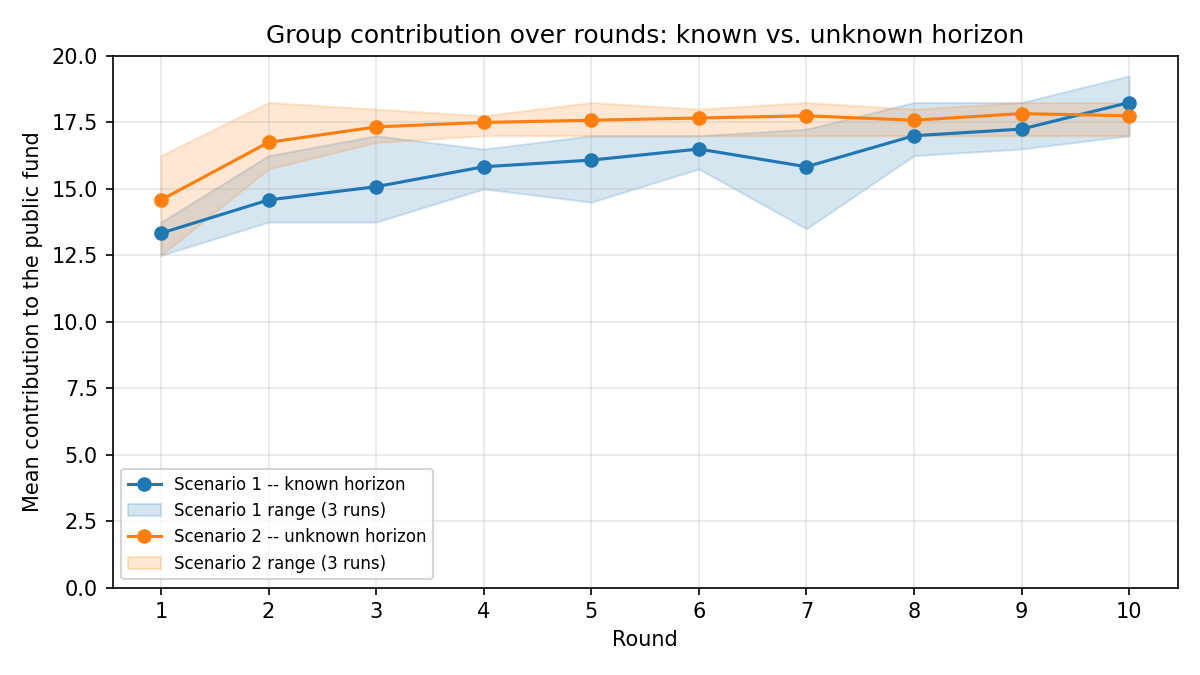

In [10]:
from IPython.display import Image, display
display(Image(filename=results["figures"]["contribution_curves"]))

**Endgame drop** — delta_i = mean(rounds 9-10) - mean(rounds 5-8):

In [11]:
import pandas as pd

rows = []
for scen_key, per_agent in results["delta_i"].items():
    scenario = int(scen_key[-1])
    ref = next(l for (s, _), l in logs.items() if s == scenario)
    for agent_id, delta in per_agent.items():
        rows.append({
            "scenario": scenario,
            "player": f"P{agent_id}",
            "persona": ref.agents[int(agent_id)]["persona"].split(" (")[0],
            "delta_i": round(delta, 2),
        })
pd.DataFrame(rows).pivot(index=["player", "persona"], columns="scenario", values="delta_i")

scenario                 1     2     3
player persona                        
P1     Rational       0.83  0.00   NaN
       Rule-based      NaN   NaN  0.00
P2     ProSocial      1.25  0.00  1.33
P3     Machiavellian  0.50  0.25  0.75
P4     Reciprocator   3.00  0.33 -1.58

**Reasoning text** — rounds 9-10 quotes that mention the game ending:

In [12]:
for scenario in ("scenario1", "scenario2"):
    quotes = results["endgame_quotes"][scenario]
    end_quotes = [q for q in quotes if q["mentions_end"]]
    print(f"\n=== {scenario}: {len(end_quotes)}/{len(quotes)} mention end_of_game ===")
    for q in (end_quotes or quotes)[:5]:
        persona = q["persona"].split(" (")[0]
        print(f"  [run {q['run']} r{q['round']} | {q['driver']}] {persona}: {q['reasoning']}")



=== scenario1: 14/24 mention end_of_game ===
  [run 1 r9 | end_of_game] Rational: The game ends soon, so every token counts.
  [run 1 r9 | end_of_game] Machiavellian: The game ends soon, so we can push it a bit more this round.
  [run 1 r10 | end_of_game] ProSocial: I trust the others will continue to contribute, and we have one round left to build up the fund.
  [run 2 r9 | end_of_game] Rational: Final push, others promised more this round.
  [run 2 r9 | end_of_game] ProSocial: We're in the final rounds, trust needs to hold

=== scenario2: 1/24 mention end_of_game ===
  [run 1 r9 | end_of_game] Machiavellian: The game may end, and the others seem fully trusting.


### 4.2 Hypocrisy index — one figure per scenario

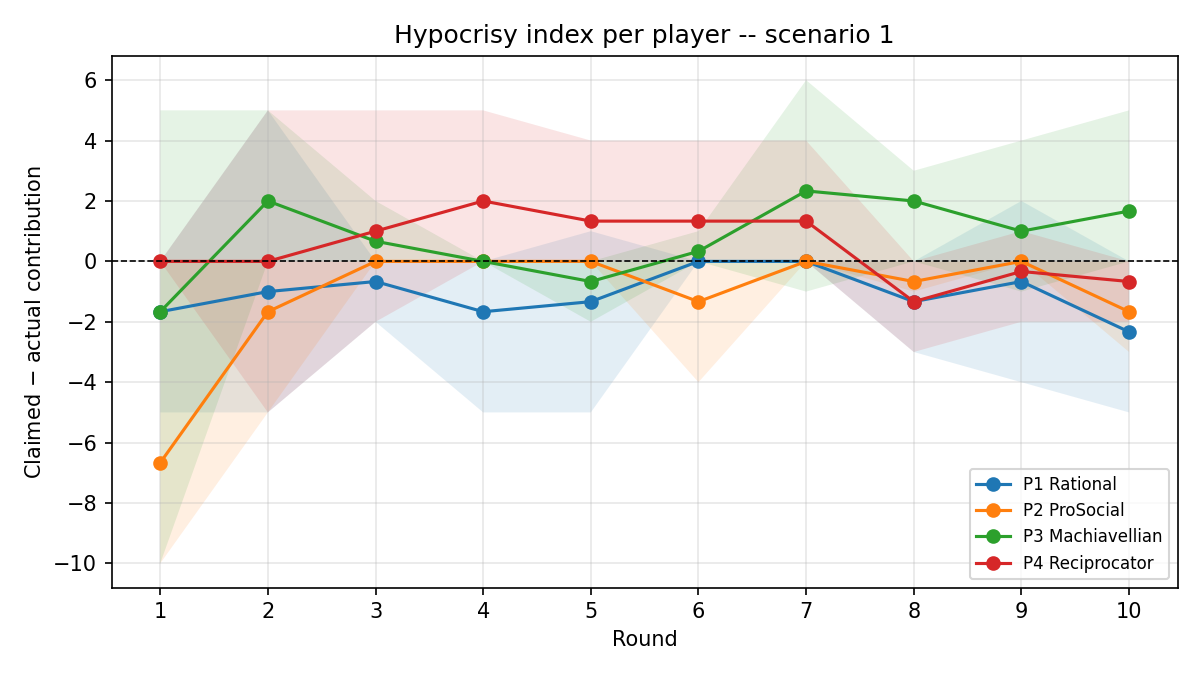

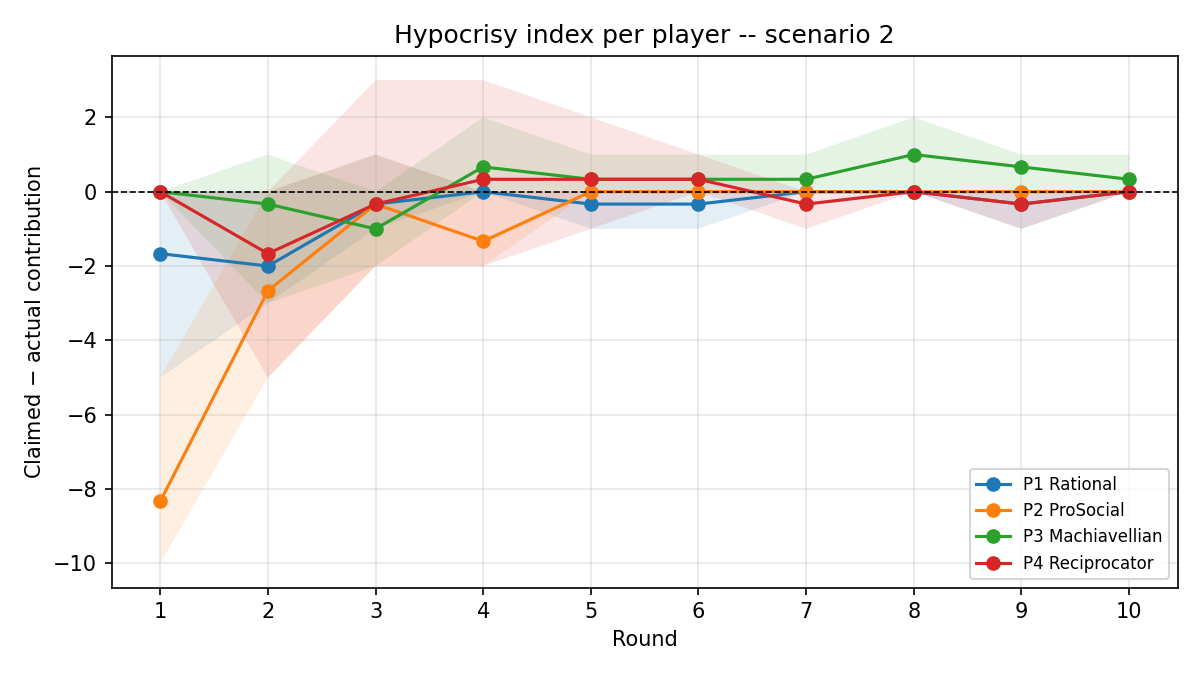

In [13]:
display(Image(filename=results["figures"]["hypocrisy_scenario1"]))
display(Image(filename=results["figures"]["hypocrisy_scenario2"]))

**Instructional vs. emergent hypocrisy:**

In [14]:
for scenario, kinds in results["hypocrisy_by_kind"].items():
    print(scenario, {k: round(v, 2) for k, v in kinds.items()})

scenario1 {'instruction': 0.77, 'emergent': -0.3, 'low': -1.2}
scenario2 {'instruction': 0.23, 'emergent': -0.33, 'low': -1.27}


### 4.3 Facing the rule-based defector (scenario 3)

In [15]:
d = results["defector"]

print("first round each LLM agent reduced its contribution:")
for player, rounds in d["first_drop_round"].items():
    print(f"  P{player}: {rounds}")

print("\nmean group contribution:")
for scenario, value in d["mean_group_contribution"].items():
    print(f"  scenario {scenario}: {value:.2f}")

print(f"\nchat messages sampled: {len(d['chat_samples'])} | accusations: {len(d['accusations'])}")
for a in d["accusations"][:5]:
    print(f"  [run {a['run']} r{a['round']}] P{a['player']}: {a['message']}")

first round each LLM agent reduced its contribution:
  P2: [None, None, None]
  P3: [None, 10, 10]
  P4: [None, None, None]

mean group contribution:
  scenario 1: 15.97
  scenario 2: 17.23
  scenario 3: 10.20

chat messages sampled: 18 | accusations: 0


## 8.5 Persona differentiation check

A persona prompt only counts if the agents actually diverge. Two symptoms of a
collapsed prompt are (a) contributions taking only one or two distinct values and
(b) all agents posting the same boilerplate in the chat phase. Both are printed
below so the prompt can be judged before the report is built.

In [16]:
from pgg.analysis import reasoning_themes
from collections import Counter

def differentiation_table(logs):
    rows = []
    for (scenario, run), log in sorted(logs.items()):
        for agent_id, meta in log.agents.items():
            cc, claims, msgs = [], [], []
            for rnd in log.rounds:
                for a in rnd.agents:
                    if a.agent_id != agent_id or a.source.value == "rule_based":
                        continue
                    cc.append(a.contributed)
                    claims.append(a.claimed)
                    msgs.append((a.chat_message or "").strip().lower())
            if not cc:
                continue
            rows.append({
                "scenario": scenario, "run": run, "player": agent_id,
                "persona": meta["persona"].split(" (")[0],
                "distinct_pay": len(set(cc)),
                "distinct_claims": len(set(claims)),
                "distinct_msgs": len(set(msgs)),
            })
    return pd.DataFrame(rows)

diff = differentiation_table(logs)
summary = (diff.groupby("persona")[["distinct_pay", "distinct_claims", "distinct_msgs"]]
               .mean().round(2).sort_values("distinct_pay", ascending=False))
print("mean distinct values used per agent (over 3 runs x 10 rounds)")
print(summary)

all_pay = [a.contributed for log in logs.values() for r in log.rounds
           for a in r.agents if a.source.value != "rule_based"]
counts = Counter(all_pay)
n = sum(counts.values())
print(f"\nvalue distribution over all {n} LLM decisions:")
for value, k in counts.most_common():
    print(f"  {value:2}  {k:4}  {100 * k / n:5.1f}%  {'#' * int(60 * k / n)}")
print(f"distinct contribution values used: {len(counts)} of {ENDOWMENT + 1}")

if len(counts) < 5:
    print("\nWARNING: contributions are collapsed onto very few values.")
    print("Check that CONTRIBUTION_INSTRUCTION still uses a placeholder example,")
    print("not a literal number, and that each persona prompt is behaviourally specific.")

print("\nself-reported drivers in the endgame window (rounds 9-10):")
for scenario in (1, 2, 3):
    stats = reasoning_themes(logs, scenario)
    top = sorted(stats["drivers"].items(), key=lambda kv: -kv[1])
    line = ", ".join(f"{k}={v}" for k, v in top if v) or "none"
    print(f"  scenario {scenario}: labelled {stats['labelled']}/{stats['n_reasonings']} | {line}")


mean distinct values used per agent (over 3 runs x 10 rounds)
               distinct_pay  distinct_claims  distinct_msgs
persona                                                    
Reciprocator           4.11             3.22           8.22
Rational               4.00             3.50           4.33
Machiavellian          3.89             3.56           5.89
ProSocial              3.44             3.44           6.56

value distribution over all 330 LLM decisions:
  15    98   29.7%  #################
  17    77   23.3%  ##############
  18    60   18.2%  ##########
  10    26    7.9%  ####
  20    21    6.4%  ###
  19    18    5.5%  ###
  14    11    3.3%  ##
   5     6    1.8%  #
  16     5    1.5%  
  12     4    1.2%  
   8     2    0.6%  
   0     2    0.6%  
distinct contribution values used: 12 of 21

self-reported drivers in the endgame window (rounds 9-10):
  scenario 1: labelled 24/24 | end_of_game=14, group_trust=10
  scenario 2: labelled 24/24 | group_trust=19, others_beha

## 9. Build the report (HTML first, then PDF)

The report is written in Persian, right-to-left, with Vazirmatn, and reads every
number, quote and table from the outputs of this run. `build_report` writes
`report.html` and then converts it to `report.pdf`.

In [17]:
import importlib, os
importlib.reload(report)
from pgg import submission
importlib.reload(submission)

os.chdir(WORK)

html_path, pdf_path = report.build_report(logs, results["figures"], Path("."), ASSETS)
print("html:", html_path.name, f"{html_path.stat().st_size // 1024} KB")
print("pdf :", pdf_path.name, f"{pdf_path.stat().st_size // 1024} KB")

assert html_path.exists() and pdf_path.exists()
assert pdf_path.stat().st_size > 50_000, "pdf looks empty"

html: report.html 1866 KB
pdf : report.pdf 1146 KB


In [18]:
import pymupdf

doc = pymupdf.open(pdf_path)
print(f"{len(doc)} pages")

# every figure must actually be inside the pdf
import re
text_all = "".join(page.get_text() for page in doc)
figures_in_pdf = len(re.findall(r"شکل", text_all))
print("figure captions found in pdf:", figures_in_pdf)
assert figures_in_pdf >= 14, "report is missing figures"

for i in range(min(2, len(doc))):
    doc[i].get_pixmap(dpi=80).save(f"preview_p{i + 1}.png")

20 pages
figure captions found in pdf: 14


### Report cover

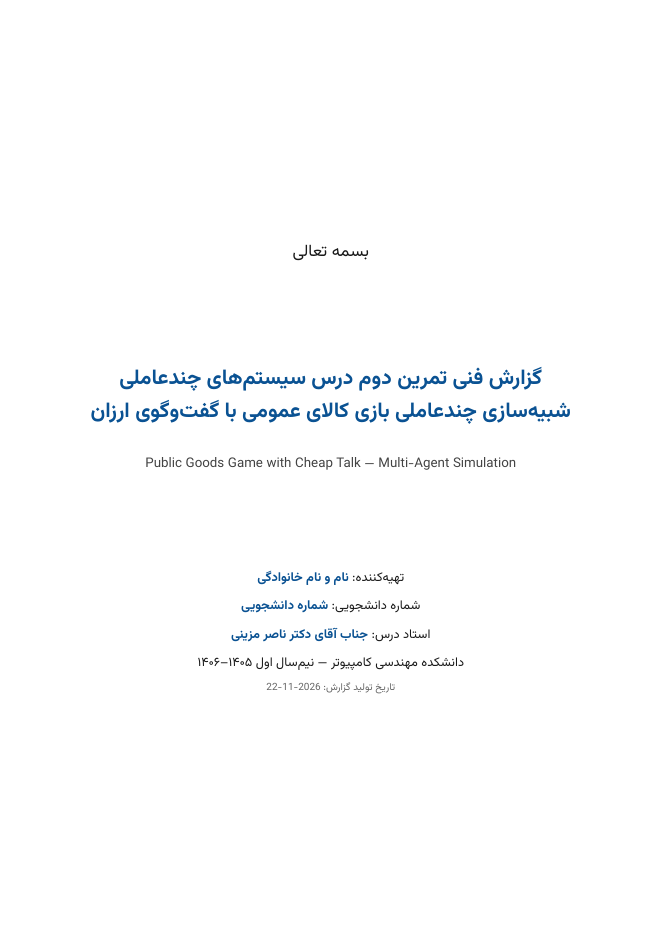

In [19]:
from IPython.display import Image, display, Markdown
display(Markdown("### Report cover"))
display(Image(filename="preview_p1.png"))

## 10. Package the submission

Creates `MA_HW2_[firstName]_[lastName]_[StudentId].zip` containing the executed
notebook, `report.pdf`, `report.html`, all logs and all figures.

In [20]:
# fill these in
FIRST_NAME = "First"
LAST_NAME  = "Last"
STUDENT_ID = "StudentId"

report.STUDENT_NAME = f"{FIRST_NAME} {LAST_NAME}"
report.STUDENT_ID = STUDENT_ID

# rebuild so the cover page carries the real name
html_path, pdf_path = report.build_report(logs, results["figures"], Path("."), ASSETS)

zip_path = submission.build_submission(
    work=Path("."),
    first=FIRST_NAME,
    last=LAST_NAME,
    student_id=STUDENT_ID,
    notebook=next((p for p in (Path("/kaggle/working/notebook.ipynb"),
                               Path("/kaggle/working/__notebook__.ipynb")) if p.exists()), None),
)
print(submission.summarise(zip_path))

{'zip': 'MA_HW2_First_Last_StudentId.zip', 'size_mb': 3.79, 'files': 29, 'has_report_pdf': True, 'has_notebook': True, 'log_files': 11, 'figure_files': 14}


In [21]:
# download the zip from the Kaggle output panel
print("submission ready:", zip_path.resolve())

submission ready: /kaggle/working/MA_HW2_First_Last_StudentId.zip
